In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

In [2]:
batch_size = 512
device = torch.device('cpu')
trainloader = torch.utils.data. DataLoader(datasets.MNIST('data', train=True, download = True, transform=transforms. Compose([transforms. ToTensor()])), batch_size=batch_size, shuffle=True)
testloader = torch.utils.data.DataLoader(datasets.MNIST('data', train=False, download=True, transform=transforms. Compose([transforms . ToTensor()])), batch_size=batch_size, shuffle=True)

100.0%
100.0%
100.0%
100.0%


单张图片信息：
  形状 (C,H,W) : (1, 28, 28)
  dtype        : torch.float32
  标签         : 9
  像素范围     : min=0.0000, max=1.0000
  均值/标准差  : 0.1168 / 0.2958
  展平维度     : 784 (28*28)


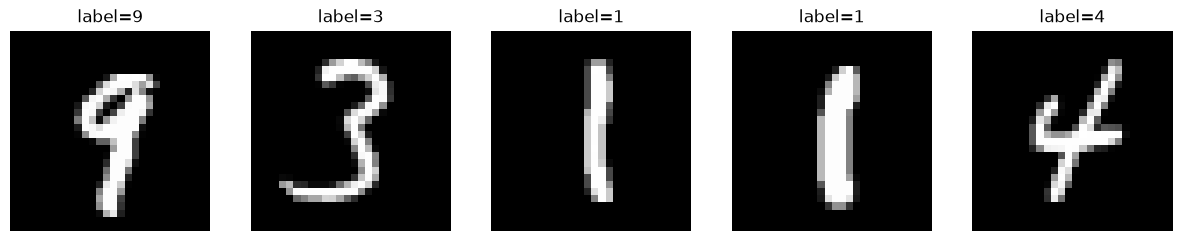

In [3]:
import matplotlib.pyplot as plt

# 从已定义好的 trainloader 取一个 batch，只取前 5 张（不覆盖 trainloader，避免影响后面训练）
images, labels = next(iter(trainloader))
images, labels = images[:5], labels[:5]

# 1. 单张图片信息
img = images[0]
print("单张图片信息：")
print(f"  形状 (C,H,W) : {tuple(img.shape)}")
print(f"  dtype        : {img.dtype}")
print(f"  标签         : {labels[0].item()}")
print(f"  像素范围     : min={img.min():.4f}, max={img.max():.4f}")
print(f"  均值/标准差  : {img.mean():.4f} / {img.std():.4f}")
print(f"  展平维度     : {img.numel()} (28*28)")

# 2. 画出前 5 张
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i in range(5):
    axes[i].imshow(images[i].squeeze(0), cmap='gray')
    axes[i].set_title(f"label={labels[i].item()}")
    axes[i].axis('off')
plt.show()

In [7]:
# 手动实现LeNet-5网络结构

class Net(nn.Module):
    def __init__(self):
        super(Net,self).__init__()
        self.conv1=nn.Conv2d(1, 6, kernel_size=5, padding=2)    #输入通道1,输出通道6,卷积核5x5,padding=2
        self.conv2=nn.Conv2d(6, 16, kernel_size=5)              #输入通道6,输出通道16,卷积核5x5
        self.fc1=nn.Linear(5 * 5 * 16, 120)                     #全连接层,输入5*5*16,输出120
        self.fc2=nn.Linear(120, 84)                             #全连接层,输入120,输出84
        self.clf=nn.Linear(84, 10)                              #分类层,输入84,输出10

    def forward(self,x):
        # conv1
        x = self.conv1(x)
        print(f"conv1:{x.shape}\n")
        
        # 激活函数sigmoid()
        x = torch.sigmoid(x)
        print(f"sigmoid1:{x.shape}\n")

        # 平均池化层,kernel=2x2,步长2
        x = F.avg_pool2d(x, kernel_size=2, stride=2)
        print(f"avg_pool2d_1:{x.shape}\n")

        # conv2
        x = self.conv2(x)
        print(f"conv2:{x.shape}\n")

        # 激活函数sigmoid()
        x = torch.sigmoid(x)
        print(f"sigmoid2:{x.shape}\n")

        # 平均池化层,2x2,步长2
        x = F.avg_pool2d(x, kernel_size=2, stride=2)
        print(f"avg_pool2d_2:{x.shape}\n")

        # 展平,从第1维开始展平（保留batch维）
        x = x.flatten(1)
        print(f"从第1维开始展平结果，flatten:{x.shape}\n")

        # 全连接层1
        x = self.fc1(x)
        print(f"全连接层1,fc1:{x.shape}\n")

        # 激活函数sigmoid()
        x = torch.sigmoid(x)
        print(f"sigmoid3:{x.shape}\n")

        # 全连接层2
        x = self.fc2(x)
        print(f"全连接层2,fc2:{x.shape}\n")

        # 激活函数sigmoid()
        x = torch.sigmoid(x)
        print(f"sigmoid4:{x.shape}\n")

        # 分类层（不再加softmax，由CrossEntropyLoss内部处理）
        x = self.clf(x)
        print(f"分类层，clf:{x.shape}\n")

        return x

In [9]:
model = Net().to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-2)
model

epochs = 30
accs, losses = [], []
for epoch in range(epochs):
    for batch_idx, (x,y) in enumerate(trainloader):
        x,y = x.to(device),y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = F.cross_entropy(out,y)
        loss.backward()
        optimizer.step()

    correct = 0
    testloss = 0
    with torch.no_grad():
        for batch_idx,(x,y) in enumerate(testloader):
            x,y = x.to(device),y.to(device)
            out = model(x)
            testloss += F.cross_entropy(out,y).item()
            pred = out.max(dim=1, keepdim=True)[1]
            correct += pred.eq(y.view_as(pred)).sum().item()

    acc = correct/len(testloader.dataset)
    testloss = testloss/(batch_idx+1)
    accs.append(acc)
    losses.append(testloss)
    print(f'epoch:{epoch}, loss:{testloss:.4f}, acc:{acc:.4f}')


conv1:torch.Size([512, 6, 28, 28])

sigmoid1:torch.Size([512, 6, 28, 28])

avg_pool2d_1:torch.Size([512, 6, 14, 14])

conv2:torch.Size([512, 16, 10, 10])

sigmoid2:torch.Size([512, 16, 10, 10])

avg_pool2d_2:torch.Size([512, 16, 5, 5])

从第1维开始展平结果，flatten:torch.Size([512, 400])

全连接层1,fc1:torch.Size([512, 120])

sigmoid3:torch.Size([512, 120])

全连接层2,fc2:torch.Size([512, 84])

sigmoid4:torch.Size([512, 84])

分类层，clf:torch.Size([512, 10])

conv1:torch.Size([512, 6, 28, 28])

sigmoid1:torch.Size([512, 6, 28, 28])

avg_pool2d_1:torch.Size([512, 6, 14, 14])

conv2:torch.Size([512, 16, 10, 10])

sigmoid2:torch.Size([512, 16, 10, 10])

avg_pool2d_2:torch.Size([512, 16, 5, 5])

从第1维开始展平结果，flatten:torch.Size([512, 400])

全连接层1,fc1:torch.Size([512, 120])

sigmoid3:torch.Size([512, 120])

全连接层2,fc2:torch.Size([512, 84])

sigmoid4:torch.Size([512, 84])

分类层，clf:torch.Size([512, 10])

conv1:torch.Size([512, 6, 28, 28])

sigmoid1:torch.Size([512, 6, 28, 28])

avg_pool2d_1:torch.Size([512, 6, 14, 14

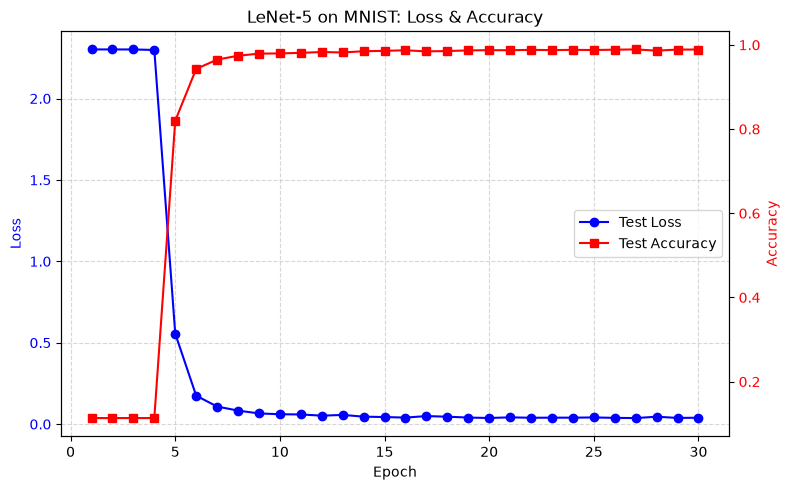

In [10]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(losses) + 1)

fig, ax1 = plt.subplots(figsize=(8, 5))

# 左轴：loss
ax1.plot(epochs_range, losses, 'b-o', label='Test Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss', color='b')
ax1.tick_params(axis='y', labelcolor='b')
ax1.grid(True, linestyle='--', alpha=0.5)

# 右轴：accuracy
ax2 = ax1.twinx()
ax2.plot(epochs_range, accs, 'r-s', label='Test Accuracy')
ax2.set_ylabel('Accuracy', color='r')
ax2.tick_params(axis='y', labelcolor='r')

# 合并图例
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right')

plt.title('LeNet-5 on MNIST: Loss & Accuracy')
plt.tight_layout()
plt.show()

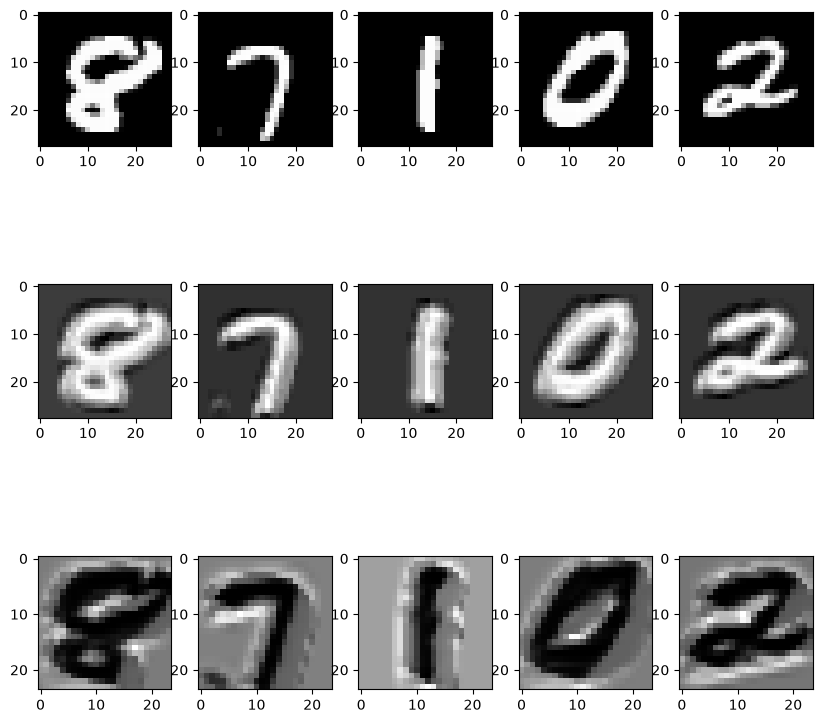

In [11]:
feature1 = F.sigmoid(model.conv1(x))
# feature1 = F.avg_pool2d(feature1,kernel_size=2,stride=2)
feature2 = F.sigmoid(model.conv2(feature1))
# feature2 = F.avg_poo12d(feature2,kernel_size=2,stride=2)

n = 5
img =x.detach().cpu().numpy()[:n]
feature_map1 = feature1.detach().cpu().numpy()[:n]
feature_map2 = feature2.detach().cpu().numpy()[:n]

fig, ax = plt.subplots(3, n, figsize=(10,10))
for i in range(n):
    ax[0,i].imshow(img[i].sum(0),cmap='gray')
    # ax[0,i].axis('off')
    ax[1,i].imshow(feature_map1[i].sum(0),cmap='gray')
    # ax[1,i].axis('off')
    ax[2,i].imshow(feature_map2[i].sum(0),cmap='gray')
    # ax[1,i].axis('off')
plt.show()